# **MID EXAM MODEL DEPLOYMENT**

**NO 1 ( Exploratory Data Analysis & Modeling )**  
**Name : Stevanus Gerald Marconus**  
**NIM : 2802392500**

**LAMPIRAN**  
link streamlit app -> https://placement-salary-prediction-sgm-2802392500-mdmidexam.streamlit.app/  
link Video -> https://youtu.be/RuZc80pSx7Y?si=qyTyN5SGTwAePJmR 

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.preprocessing import LabelEncoder, OneHotEncoder, RobustScaler, StandardScaler
from sklearn.ensemble import RandomForestClassifier, RandomForestRegressor
from sklearn.linear_model import LogisticRegression, LinearRegression
from sklearn.svm import SVR
from sklearn.metrics import accuracy_score, f1_score, precision_score, recall_score, classification_report, confusion_matrix, roc_auc_score, roc_curve, mean_squared_error, r2_score, mean_absolute_error
from xgboost import XGBClassifier
from sklearn.model_selection import StratifiedKFold, cross_validate

**LOAD DATASET**

In [2]:
data_B = pd.read_csv('B.csv')
data_B

,student_id,gender,ssc_percentage,hsc_percentage,degree_percentage,cgpa,entrance_exam_score,technical_skill_score,soft_skill_score,internship_count,live_projects,work_experience_months,certifications,attendance_percentage,backlogs,extracurricular_activities,placement_status,salary_package_lpa
0,1,Male,53,79,56,8.87,50,92,90,1,3,23,4,91,4,Yes,0,0.00
1,2,Female,56,54,59,6.78,61,51,99,1,0,6,5,87,3,No,0,0.00
2,3,Male,94,83,83,7.92,91,93,84,1,1,10,2,81,2,No,1,6.92
3,4,Male,84,71,87,6.57,85,60,72,4,2,14,5,87,3,No,0,0.00
4,5,Male,58,88,74,9.01,73,52,88,1,2,20,0,60,1,No,0,0.00
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
4995,4996,Male,68,50,67,8.32,51,57,96,1,1,15,1,71,4,Yes,0,0.00
4996,4997,Female,61,52,56,9.47,61,59,62,3,4,0,3,73,5,Yes,0,0.00
4997,4998,Male,74,76,58,6.19,40,99,89,1,1,2,2,67,1,No,0,0.00
4998,4999,Female,84,67,66,8.07,40,48,92,4,1,6,4,61,0,No,0,0.00


In [3]:
data_B.head(7)

,student_id,gender,ssc_percentage,hsc_percentage,degree_percentage,cgpa,entrance_exam_score,technical_skill_score,soft_skill_score,internship_count,live_projects,work_experience_months,certifications,attendance_percentage,backlogs,extracurricular_activities,placement_status,salary_package_lpa
0,1,Male,53,79,56,8.87,50,92,90,1,3,23,4,91,4,Yes,0,0.00
1,2,Female,56,54,59,6.78,61,51,99,1,0,6,5,87,3,No,0,0.00
2,3,Male,94,83,83,7.92,91,93,84,1,1,10,2,81,2,No,1,6.92
3,4,Male,84,71,87,6.57,85,60,72,4,2,14,5,87,3,No,0,0.00
4,5,Male,58,88,74,9.01,73,52,88,1,2,20,0,60,1,No,0,0.00
5,6,Female,57,62,84,5.98,52,52,43,1,3,10,1,65,0,No,0,0.00
6,7,Male,94,52,59,9.07,85,92,43,2,0,6,1,70,5,Yes,0,0.00


In [4]:
data_B.tail(7)

,student_id,gender,ssc_percentage,hsc_percentage,degree_percentage,cgpa,entrance_exam_score,technical_skill_score,soft_skill_score,internship_count,live_projects,work_experience_months,certifications,attendance_percentage,backlogs,extracurricular_activities,placement_status,salary_package_lpa
4993,4994,Male,54,89,56,8.11,43,74,73,3,3,9,4,76,2,Yes,1,11.81
4994,4995,Male,62,68,68,5.97,65,81,80,3,3,3,4,88,0,Yes,0,0.00
4995,4996,Male,68,50,67,8.32,51,57,96,1,1,15,1,71,4,Yes,0,0.00
4996,4997,Female,61,52,56,9.47,61,59,62,3,4,0,3,73,5,Yes,0,0.00
4997,4998,Male,74,76,58,6.19,40,99,89,1,1,2,2,67,1,No,0,0.00
4998,4999,Female,84,67,66,8.07,40,48,92,4,1,6,4,61,0,No,0,0.00
4999,5000,Female,61,79,64,6.97,42,80,59,4,5,2,5,93,4,Yes,0,0.00


**Data Overview**

In [5]:
# Check dataset dimensions
data_B.shape

(5000, 18)

In [6]:
# Check dataset columns
data_B.columns

Index(['student_id', 'gender', 'ssc_percentage', 'hsc_percentage',
       'degree_percentage', 'cgpa', 'entrance_exam_score',
       'technical_skill_score', 'soft_skill_score', 'internship_count',
       'live_projects', 'work_experience_months', 'certifications',
       'attendance_percentage', 'backlogs', 'extracurricular_activities',
       'placement_status', 'salary_package_lpa'],
      dtype='object')

In [7]:
#Check dataset information
data_B.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5000 entries, 0 to 4999
Data columns (total 18 columns):
 #   Column                      Non-Null Count  Dtype  
---  ------                      --------------  -----  
 0   student_id                  5000 non-null   int64  
 1   gender                      5000 non-null   object 
 2   ssc_percentage              5000 non-null   int64  
 3   hsc_percentage              5000 non-null   int64  
 4   degree_percentage           5000 non-null   int64  
 5   cgpa                        5000 non-null   float64
 6   entrance_exam_score         5000 non-null   int64  
 7   technical_skill_score       5000 non-null   int64  
 8   soft_skill_score            5000 non-null   int64  
 9   internship_count            5000 non-null   int64  
 10  live_projects               5000 non-null   int64  
 11  work_experience_months      5000 non-null   int64  
 12  certifications              5000 non-null   int64  
 13  attendance_percentage       5000 

In [8]:
# Check for any missing values
data_B.isnull().sum()

student_id                    0
gender                        0
ssc_percentage                0
hsc_percentage                0
degree_percentage             0
cgpa                          0
entrance_exam_score           0
technical_skill_score         0
soft_skill_score              0
internship_count              0
live_projects                 0
work_experience_months        0
certifications                0
attendance_percentage         0
backlogs                      0
extracurricular_activities    0
placement_status              0
salary_package_lpa            0
dtype: int64

In [9]:
# Check for any duplicated data
print(f"Jumlah data duplikat : {data_B.duplicated().sum()}")

Jumlah data duplikat : 0


In [10]:
# Check for summary statistics
data_B.describe().T

,count,mean,std,min,25%,50%,75%,max
student_id,5000.0,2500.500000,1443.520003,1.0,1250.7500,2500.5,3750.25,5000.00
ssc_percentage,5000.0,72.425800,13.199642,50.0,61.0000,72.0,84.00,95.00
hsc_percentage,5000.0,71.910800,12.842781,50.0,61.0000,72.0,83.00,94.00
degree_percentage,5000.0,71.845200,10.013196,55.0,63.0000,72.0,80.00,89.00
cgpa,5000.0,7.678326,1.237084,5.5,6.6175,7.7,8.75,9.80
entrance_exam_score,5000.0,69.197800,17.325528,40.0,54.0000,69.0,84.00,99.00
technical_skill_score,5000.0,69.651000,17.179704,40.0,55.0000,70.0,84.00,99.00
soft_skill_score,5000.0,69.839600,17.170732,40.0,55.0000,69.0,85.00,99.00
internship_count,5000.0,1.987800,1.410975,0.0,1.0000,2.0,3.00,4.00
live_projects,5000.0,2.491800,1.704967,0.0,1.0000,3.0,4.00,5.00


In [11]:
# Check unique values for gender
data_B['gender'].unique()

array(['Male', 'Female'], dtype=object)

In [12]:
data_B['gender'].value_counts()

gender
Male      2504
Female    2496
Name: count, dtype: int64

In [13]:
# check unique values for exttracurricular_activities
data_B['extracurricular_activities'].unique()

array(['Yes', 'No'], dtype=object)

In [14]:
data_B['extracurricular_activities' ].value_counts()

extracurricular_activities
No     2553
Yes    2447
Name: count, dtype: int64

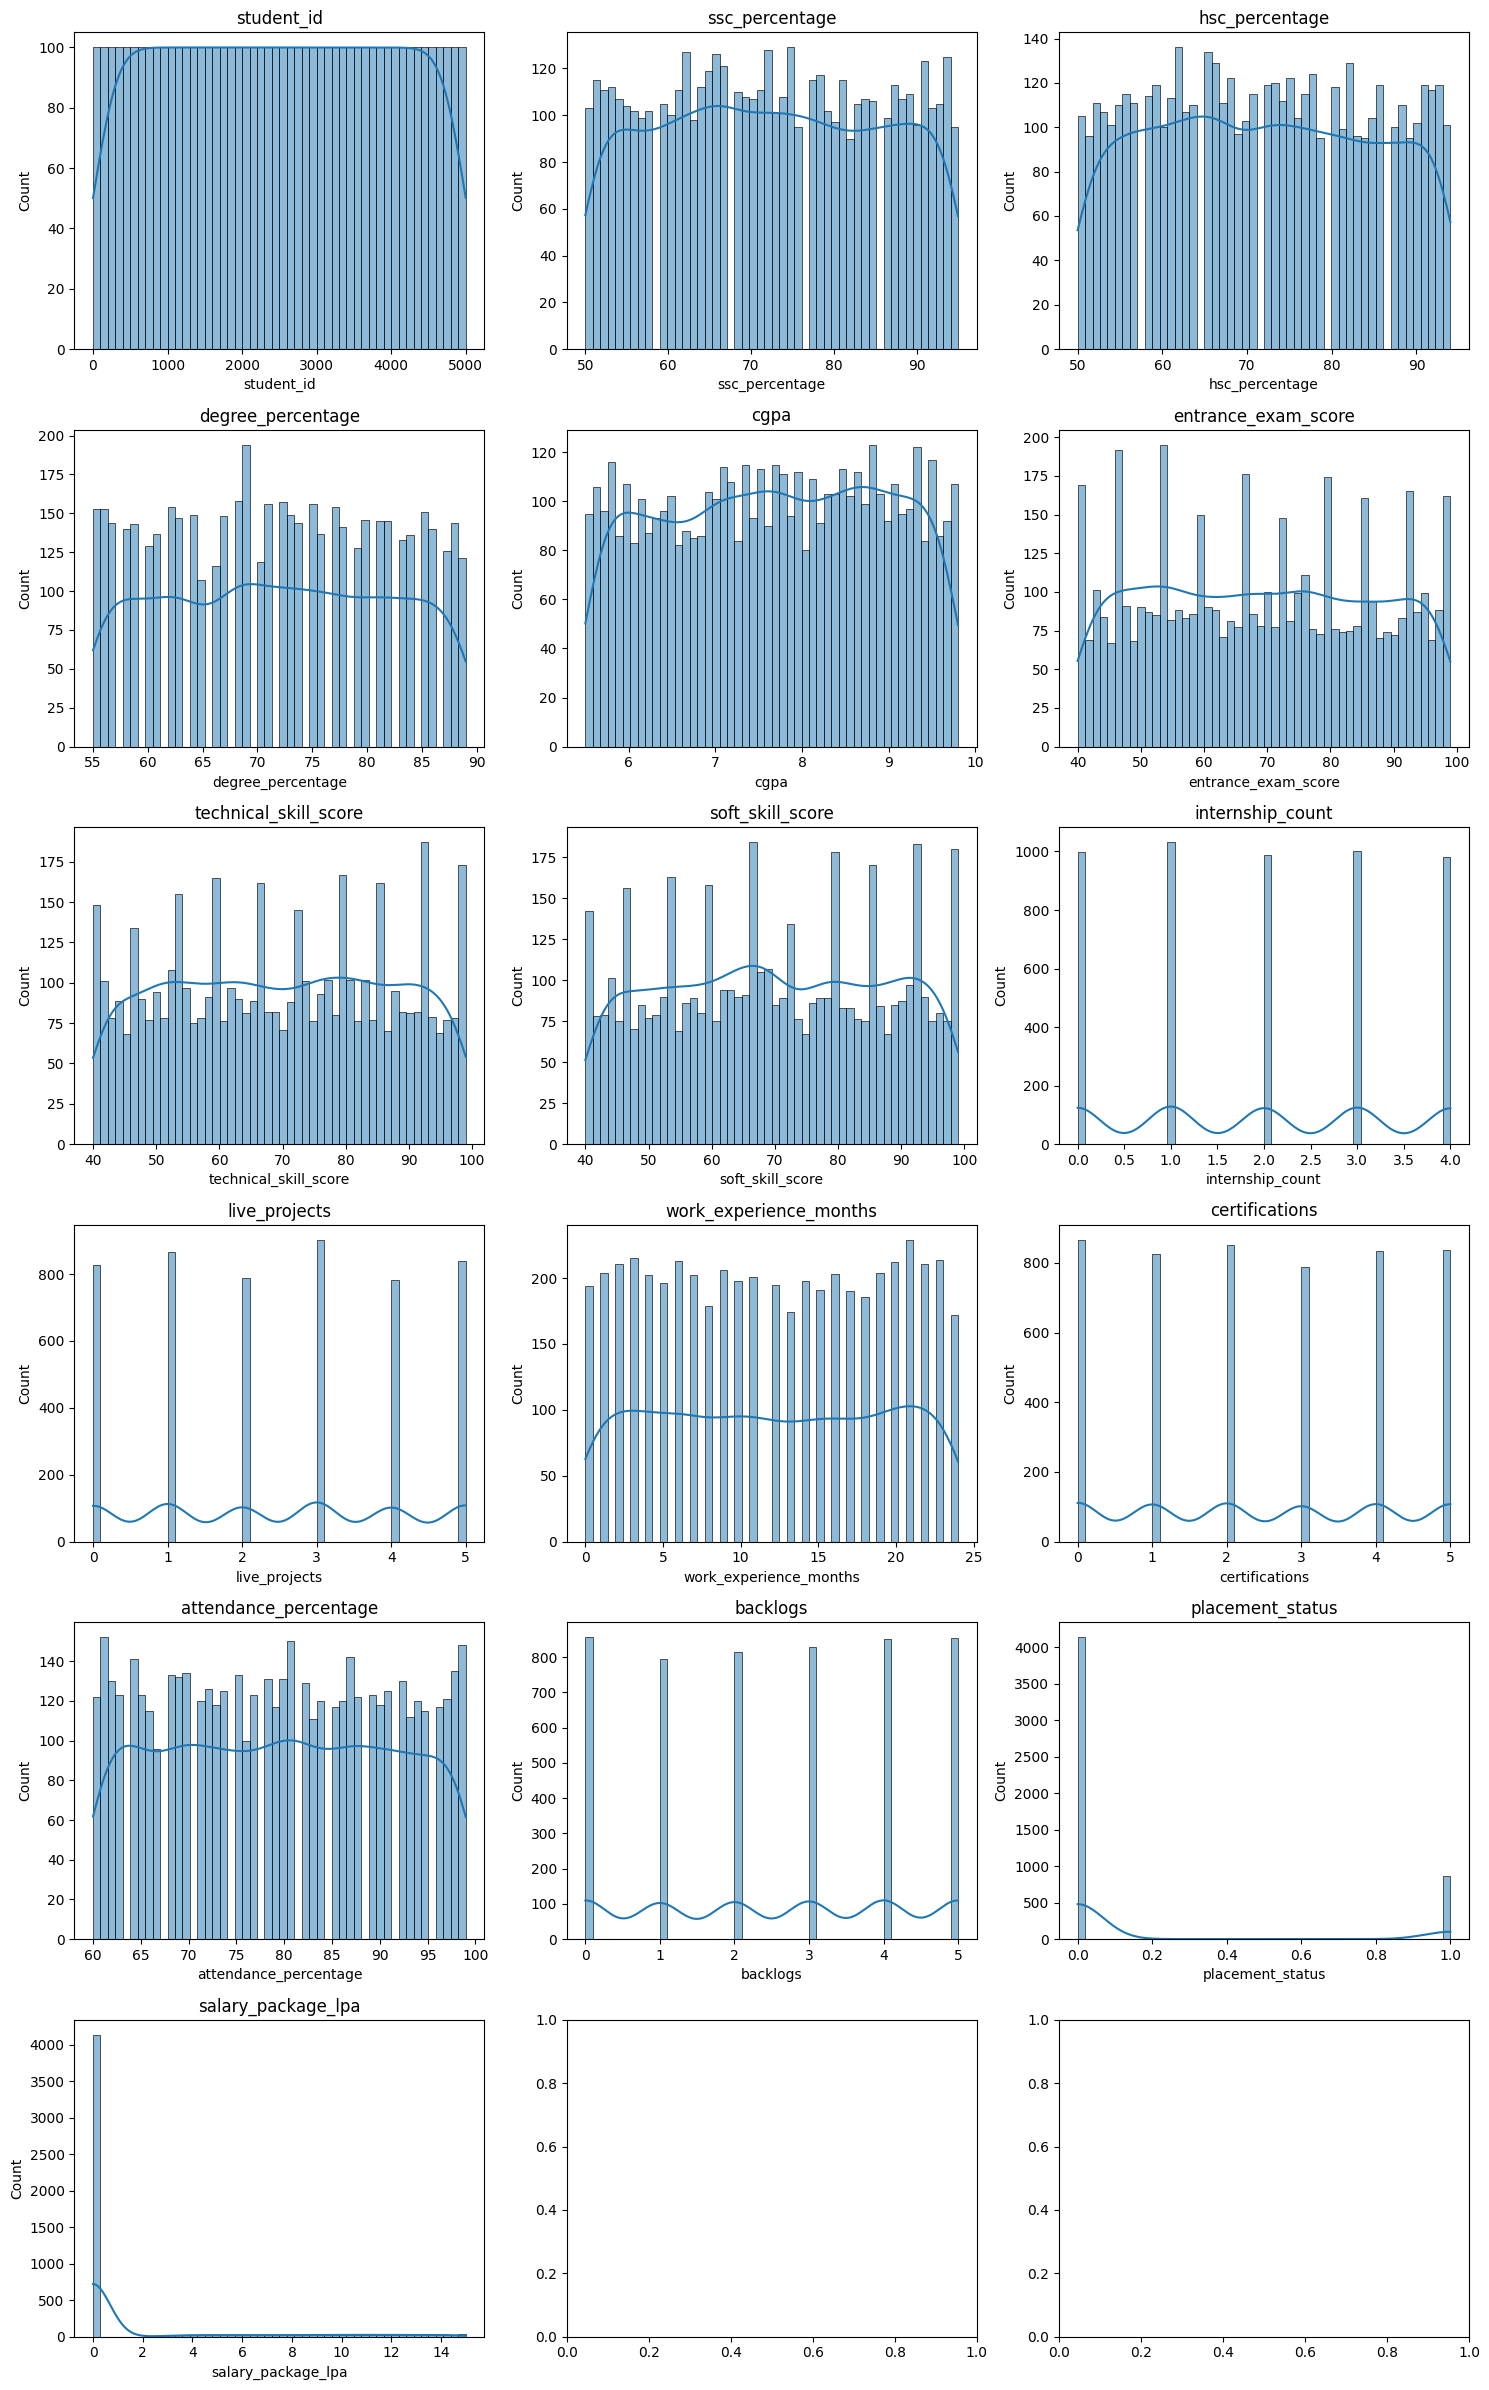

In [15]:
# Check the distribution 
num_cols = data_B.select_dtypes(include=['float64', 'int64']).columns
rows = (len(num_cols) + 2) // 3  
fig, axs = plt.subplots(rows, 3, figsize=(15, 4*rows))
axs = axs.flatten()
for i, col in enumerate(num_cols):
    sns.histplot(data_B[col], bins=50, kde=True, ax=axs[i])
    axs[i].set_title(col)

plt.tight_layout()
plt.show()

Setiap Fitur numercal pada data memiliki pola distribusi Uniform dimana semua fitur-fiturnya memiliki pola distribusi yang 'hampir' sama seragam.

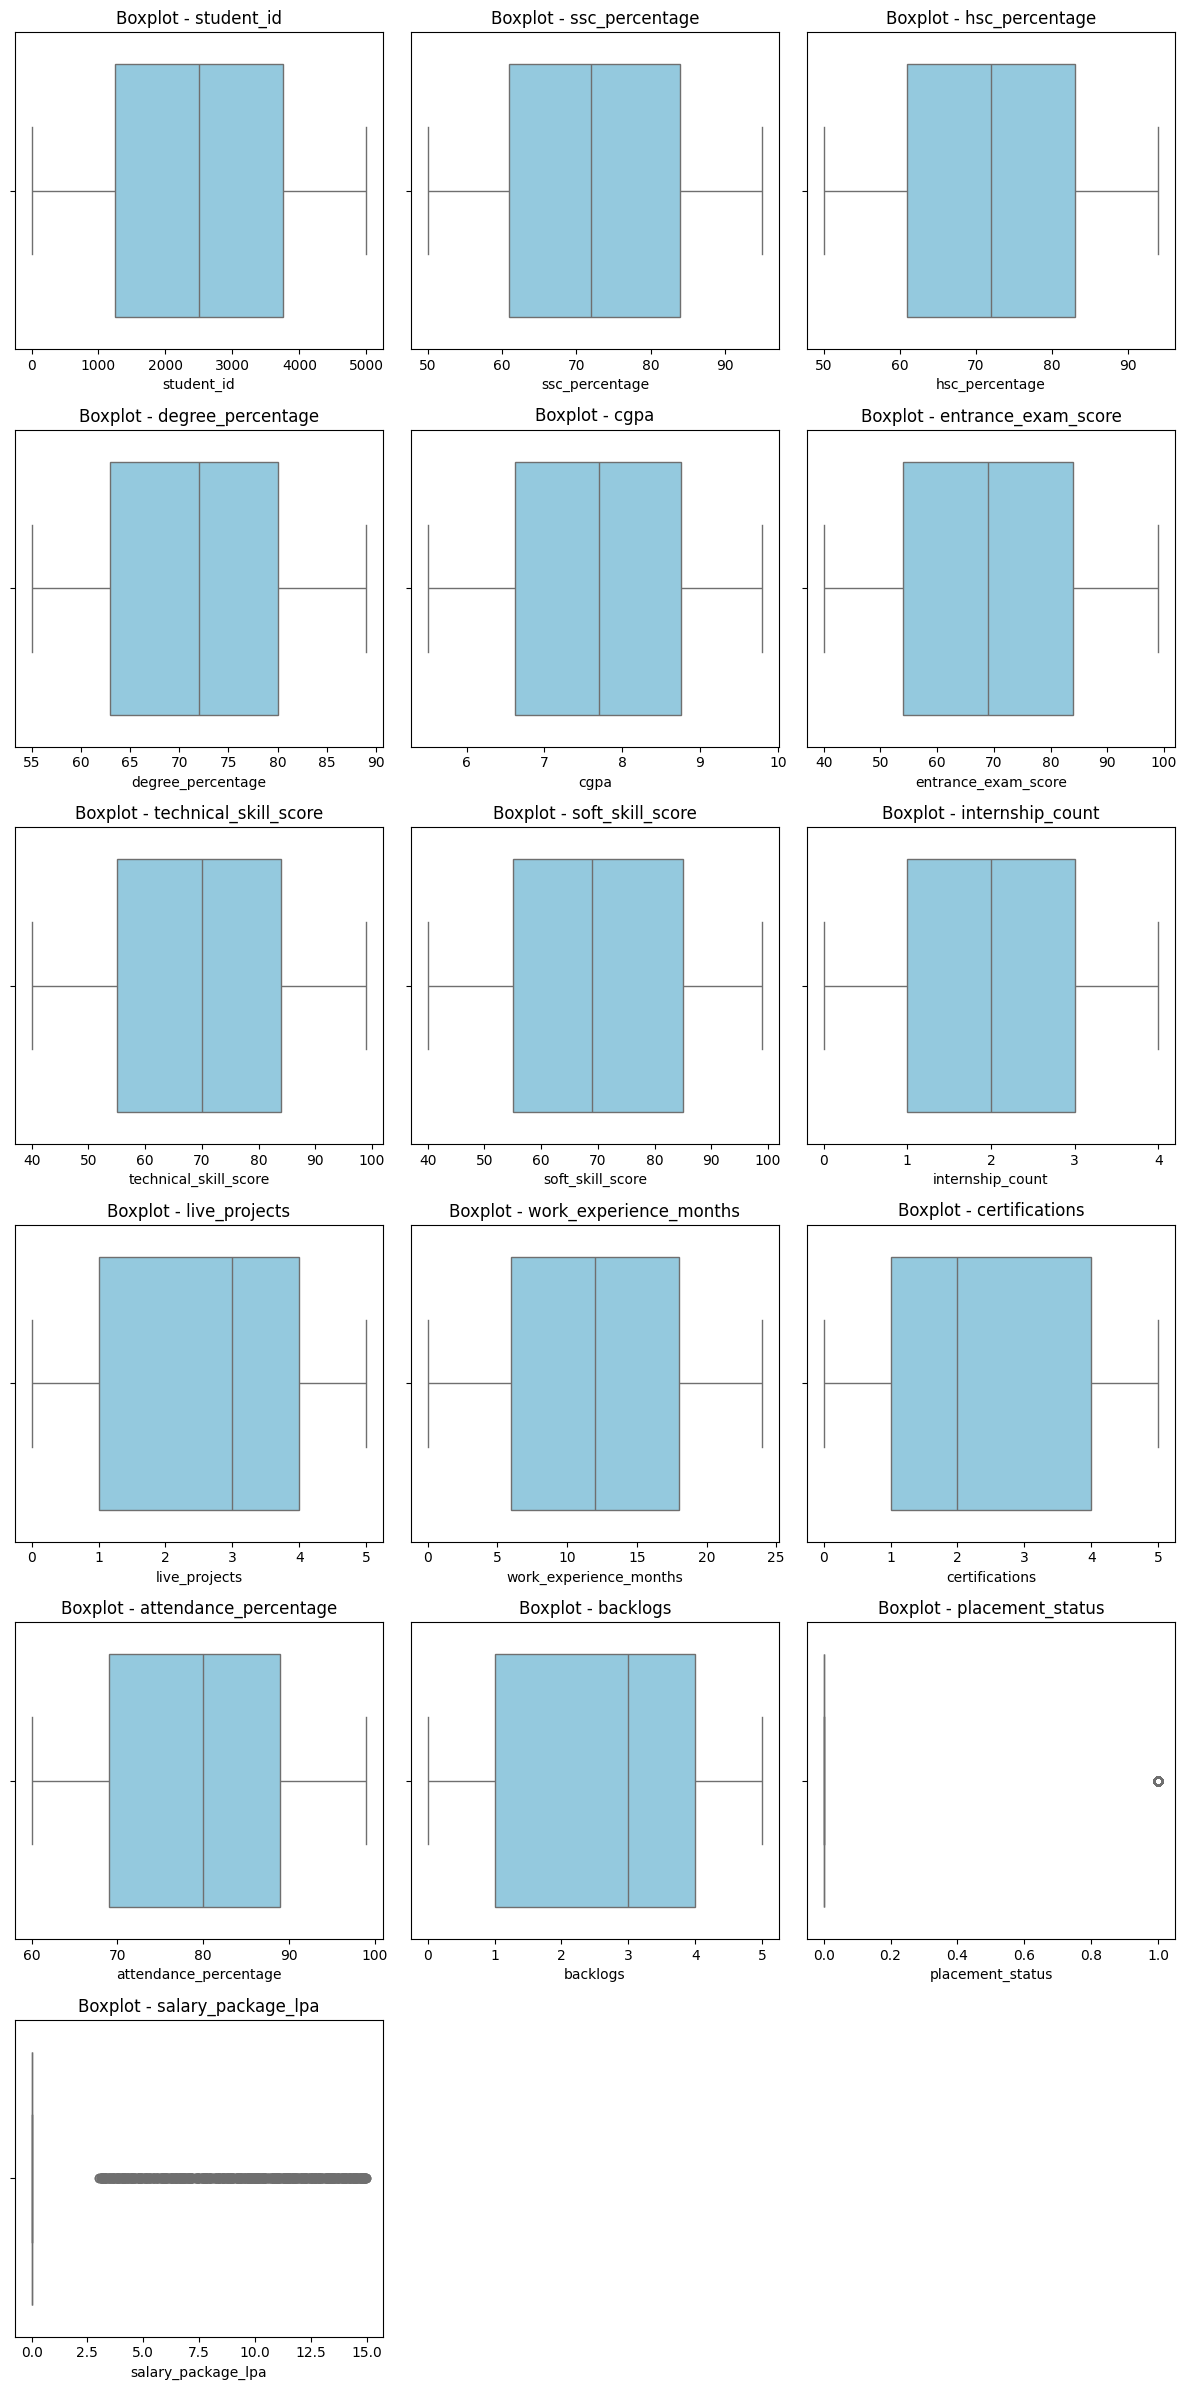

In [16]:
# Check for outliers in numerical columns with boxplot
n_cols = 3 
n_rows = (len(num_cols) + n_cols - 1) // n_cols 
plt.figure(figsize=(12, 4 * n_rows))
for i, col in enumerate(num_cols, 1):
    plt.subplot(n_rows, n_cols, i)
    sns.boxplot(x=data_B[col], color='skyblue')
    plt.title(f'Boxplot - {col}')

plt.tight_layout()
plt.show()

Tidak ada Outlier pada Bagian numerical.

**CHECK TARGET**

In [17]:
# Check Target distribution for classification 'placement_status'
data_B['placement_status'].value_counts()

placement_status
0    4134
1     866
Name: count, dtype: int64

C:\Users\Tuf Gaming\AppData\Local\Temp\ipykernel_1268\1601266802.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(x='placement_status', data=data_B, palette='viridis')


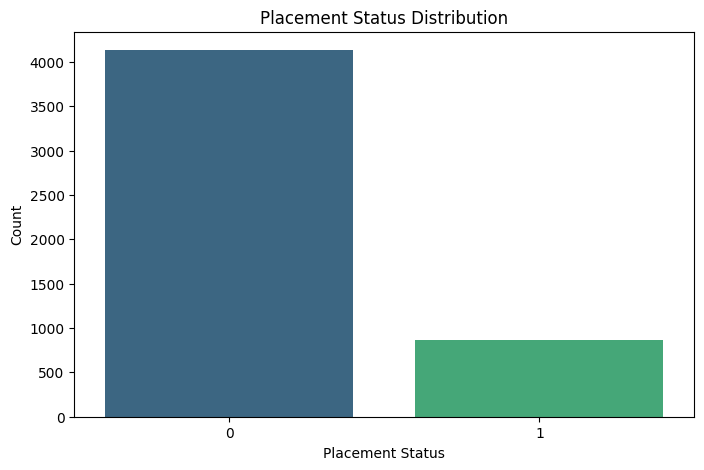

In [18]:
# Check target distribution plot for 'placement_status'
plt.figure(figsize=(8,5))
sns.countplot(x='placement_status', data=data_B, palette='viridis')
plt.title('Placement Status Distribution')
plt.xlabel('Placement Status')
plt.ylabel('Count')
plt.show()

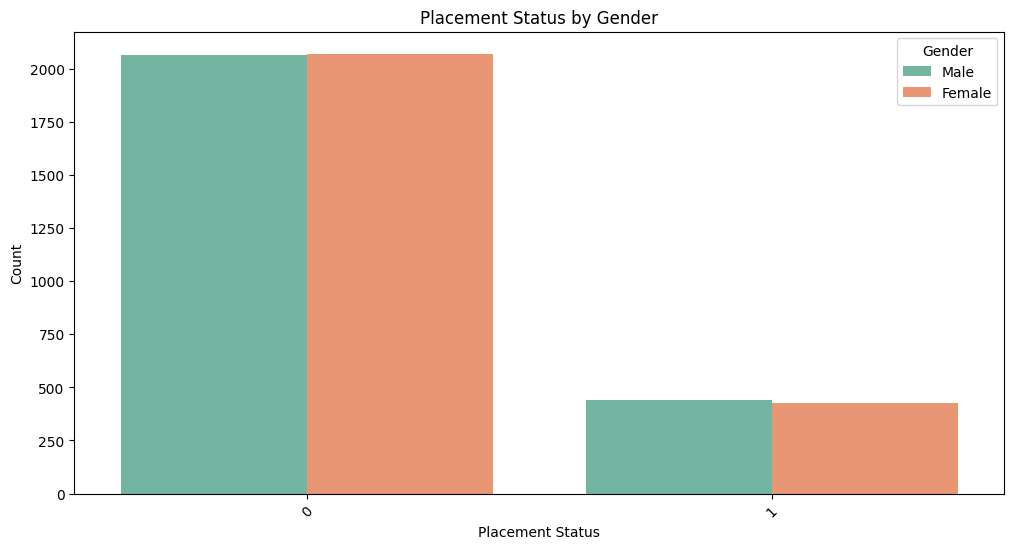

In [19]:
#Check target vs gender
plt.figure(figsize=(12,6))
sns.countplot(x='placement_status', hue='gender', data=data_B, palette='Set2')
plt.title('Placement Status by Gender')
plt.xlabel('Placement Status')
plt.ylabel('Count')
plt.xticks(rotation=45)
plt.legend(title='Gender')
plt.show()

PAda bagian ini daya mencoba melihat bagaimana peran gender terhadap klasifikasi. Sebagaimana secara umum seharusnya Gender tidaklah menjadi penentu bagi seseorang mahasiswa dikategorikan keterima kerja atau tidak. Akan tetapi berdasarkan Hasil analisa saya, terdapat sedikit indikasi bahwa gender memiliki pengaruh di mana mahasiwa bergender laki laki memiliki jumlah untuk diterima kerja 'sedikit' lebih tinggi. Maka dari itu saya memutuskan untuk menggunakan fitur gender.

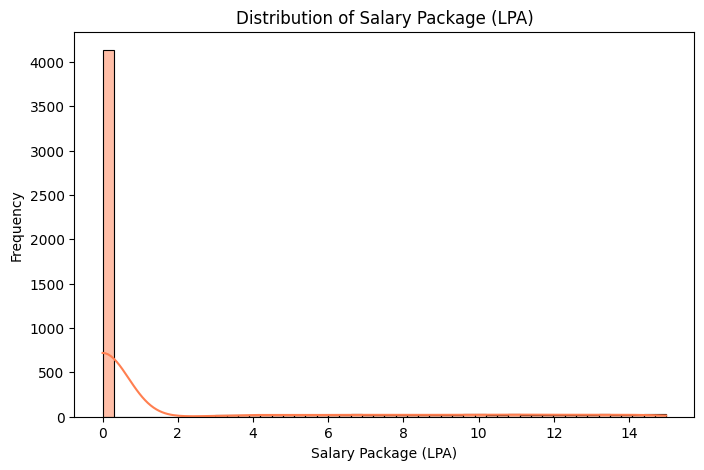

In [20]:
# Check distribution of target regression 'salary_package_lpa'
plt.figure(figsize=(8,5))
sns.histplot(data_B['salary_package_lpa'], bins=50, kde=True, color='coral')
plt.title('Distribution of Salary Package (LPA)')
plt.xlabel('Salary Package (LPA)')
plt.ylabel('Frequency')
plt.show()

C:\Users\Tuf Gaming\AppData\Local\Temp\ipykernel_1268\2011360518.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x='placement_status', y='salary_package_lpa', data=data_B, palette='Set3')


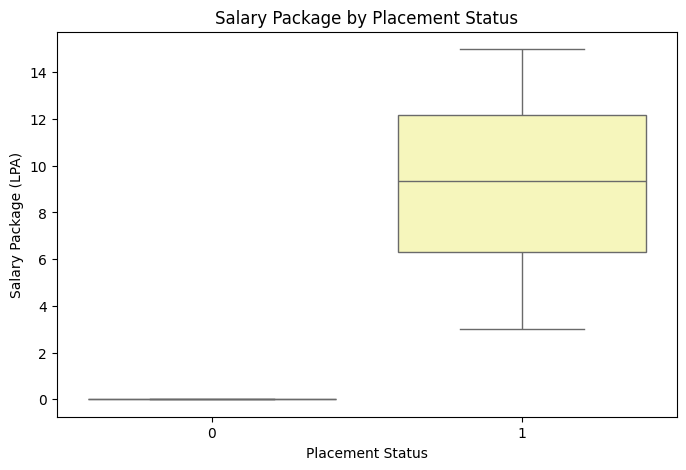

In [21]:
# validate the unplaced code with salary package
plt.figure(figsize=(8,5))
sns.boxplot(x='placement_status', y='salary_package_lpa', data=data_B, palette='Set3')
plt.title('Salary Package by Placement Status')
plt.xlabel('Placement Status')
plt.ylabel('Salary Package (LPA)')
plt.show()

In [22]:
data_B[data_B['placement_status'] == 0]

,student_id,gender,ssc_percentage,hsc_percentage,degree_percentage,cgpa,entrance_exam_score,technical_skill_score,soft_skill_score,internship_count,live_projects,work_experience_months,certifications,attendance_percentage,backlogs,extracurricular_activities,placement_status,salary_package_lpa
0,1,Male,53,79,56,8.87,50,92,90,1,3,23,4,91,4,Yes,0,0.0
1,2,Female,56,54,59,6.78,61,51,99,1,0,6,5,87,3,No,0,0.0
3,4,Male,84,71,87,6.57,85,60,72,4,2,14,5,87,3,No,0,0.0
4,5,Male,58,88,74,9.01,73,52,88,1,2,20,0,60,1,No,0,0.0
5,6,Female,57,62,84,5.98,52,52,43,1,3,10,1,65,0,No,0,0.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
4995,4996,Male,68,50,67,8.32,51,57,96,1,1,15,1,71,4,Yes,0,0.0
4996,4997,Female,61,52,56,9.47,61,59,62,3,4,0,3,73,5,Yes,0,0.0
4997,4998,Male,74,76,58,6.19,40,99,89,1,1,2,2,67,1,No,0,0.0
4998,4999,Female,84,67,66,8.07,40,48,92,4,1,6,4,61,0,No,0,0.0


In [23]:
data_B[data_B['salary_package_lpa'] > 0]

,student_id,gender,ssc_percentage,hsc_percentage,degree_percentage,cgpa,entrance_exam_score,technical_skill_score,soft_skill_score,internship_count,live_projects,work_experience_months,certifications,attendance_percentage,backlogs,extracurricular_activities,placement_status,salary_package_lpa
2,3,Male,94,83,83,7.92,91,93,84,1,1,10,2,81,2,No,1,6.92
7,8,Male,66,69,75,8.09,77,80,98,2,1,20,2,92,1,No,1,12.13
17,18,Female,95,61,87,7.10,66,65,78,0,5,4,4,66,2,Yes,1,6.76
19,20,Male,65,94,80,7.03,70,77,81,3,5,1,5,74,2,No,1,9.42
20,21,Female,81,91,55,8.40,41,74,69,0,4,1,5,60,0,Yes,1,14.85
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
4981,4982,Male,69,85,87,8.23,96,69,82,3,4,8,5,62,0,Yes,1,5.48
4985,4986,Male,51,93,71,8.73,46,73,77,0,3,20,0,87,2,Yes,1,6.73
4987,4988,Male,75,54,66,8.94,79,65,85,1,2,18,5,74,0,Yes,1,10.96
4990,4991,Male,52,75,55,7.98,59,93,55,4,3,17,1,91,1,No,1,12.24


SAya memiliki kecurigaan di mana untuk bagian target regresi salary_package_lpa mengapa banyak sekali yang memiliki 0 value. Saya berhipotesis bahwa apa mungkin value 0 pada salary ini dikibatkan oleh mahasiswa yang terkategori tidak mendapat pekerjaan?   
<br><brr>
Rupanya dugaan saya cukup terbukti di mana salary yang 0 itu diakibatkan mahasiswa dengan kategori not place (0). Dikarenakan banyak mahasiswa yang tidak mendapat pekerjaan, makaa banyak pula salary_package_lpa yang 0.

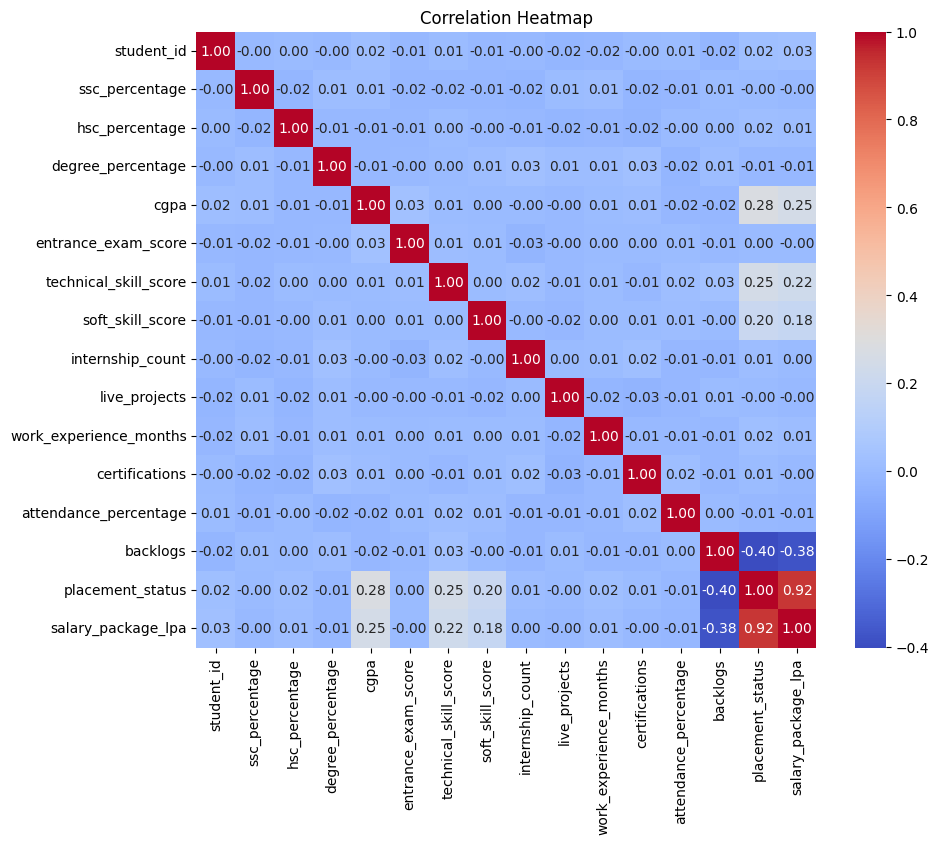

In [24]:
# check correlation between numerical features
num_cols = data_B.select_dtypes(include=['float64', 'int64']).columns
plt.figure(figsize=(10,8))
sns.heatmap(data_B[num_cols].corr(), annot=True, cmap='coolwarm', fmt='.2f')
plt.title('Correlation Heatmap')
plt.show()

Dengan menggunakan Correlation mapkita bisa melihat bahwa benar placement_status memiliki korelasi yang kuat dengan salary_package_lpa. Beritupun dengan fitur kolom lainnya. Msekpin ada beberapa fitur yang memiliki korelasi rendah akan tetapi saya memutuskan menggunakan semua fitur (kecuali student_id) karena saya sadar bahwa semua fitur yang ada tersebut merupakan data data mengenai performa dan kemampuan mahasiswa.

**Data Condition :**  
1. Dataset ini tergolong bersih tanpa adanya Missing Values.  
2. Tidak ada data yang terduplikat.  
3. DAtaset ini tidak memiliki outlier / extreme values di numerical featuresnya.  
4. Pada kolom kategorikal, tidak ada abnormal values, dan inconsistent values.  
5. Categorical harus dilakukan encoding, yakni kolom gender dan extracullcular_experiences. 
6. Terdapat kolom yang uninformative yakni Student_ID.
7. Pada Kolom target (untuk klasifikasi) terdapat indikasi imbalance, dan harus di handle untuk melakukan modeling.
8. Ada banyak nilai 0 di salary_package_lpa, dan ini kemungkinan besar karena variabel ini punya hubungan kuat sama placement_status. Jadi, karena banyak mahasiswa yang tidak mendapatkan pekerjaan (no placement), otomatis gaji mereka jadi 0.

**SPLIT THE DATASET**

In [25]:
# drop uninform columns
data_clean = data_B.drop(columns=['student_id'])
data_clean.head()

,gender,ssc_percentage,hsc_percentage,degree_percentage,cgpa,entrance_exam_score,technical_skill_score,soft_skill_score,internship_count,live_projects,work_experience_months,certifications,attendance_percentage,backlogs,extracurricular_activities,placement_status,salary_package_lpa
0,Male,53,79,56,8.87,50,92,90,1,3,23,4,91,4,Yes,0,0.00
1,Female,56,54,59,6.78,61,51,99,1,0,6,5,87,3,No,0,0.00
2,Male,94,83,83,7.92,91,93,84,1,1,10,2,81,2,No,1,6.92
3,Male,84,71,87,6.57,85,60,72,4,2,14,5,87,3,No,0,0.00
4,Male,58,88,74,9.01,73,52,88,1,2,20,0,60,1,No,0,0.00


In [26]:
data_clean.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5000 entries, 0 to 4999
Data columns (total 17 columns):
 #   Column                      Non-Null Count  Dtype  
---  ------                      --------------  -----  
 0   gender                      5000 non-null   object 
 1   ssc_percentage              5000 non-null   int64  
 2   hsc_percentage              5000 non-null   int64  
 3   degree_percentage           5000 non-null   int64  
 4   cgpa                        5000 non-null   float64
 5   entrance_exam_score         5000 non-null   int64  
 6   technical_skill_score       5000 non-null   int64  
 7   soft_skill_score            5000 non-null   int64  
 8   internship_count            5000 non-null   int64  
 9   live_projects               5000 non-null   int64  
 10  work_experience_months      5000 non-null   int64  
 11  certifications              5000 non-null   int64  
 12  attendance_percentage       5000 non-null   int64  
 13  backlogs                    5000 

In [27]:
# Set input and output features for classification
input_class = data_clean.drop(columns=['placement_status', 'salary_package_lpa'])
output_class =  data_clean['placement_status']
output_rege = data_clean['salary_package_lpa']

In [28]:
# Split the dataset (80% train, 20% test)
x_train, x_test, y_train_class, y_test_class, y_train_reg, y_test_reg = train_test_split(input_class, output_class, output_rege, test_size = 0.2, random_state = 42,stratify=output_class)


In [29]:
print('data train: ',x_train.shape)
print('data test: ',x_test.shape)

data train:  (4000, 15)
data test:  (1000, 15)


In [30]:
y_train_class 

483     0
638     0
936     0
2932    0
4154    0
       ..
1417    0
1958    0
3175    0
1878    0
4602    0
Name: placement_status, Length: 4000, dtype: int64

In [31]:
y_train_reg

483     0.0
638     0.0
936     0.0
2932    0.0
4154    0.0
       ... 
1417    0.0
1958    0.0
3175    0.0
1878    0.0
4602    0.0
Name: salary_package_lpa, Length: 4000, dtype: float64

In [32]:
y_train_class.value_counts()

placement_status
0    3307
1     693
Name: count, dtype: int64

In [33]:
x_train.describe().T

,count,mean,std,min,25%,50%,75%,max
ssc_percentage,4000.0,72.371750,13.196935,50.0,61.00,72.000,84.00,95.0
hsc_percentage,4000.0,71.945000,12.849543,50.0,61.00,72.000,83.00,94.0
degree_percentage,4000.0,71.855000,9.991969,55.0,63.00,72.000,80.00,89.0
cgpa,4000.0,7.674102,1.234766,5.5,6.61,7.695,8.74,9.8
entrance_exam_score,4000.0,69.230250,17.237590,40.0,54.00,69.000,84.00,99.0
technical_skill_score,4000.0,69.645750,17.252512,40.0,55.00,70.000,84.00,99.0
soft_skill_score,4000.0,69.963500,17.141547,40.0,56.00,70.000,85.00,99.0
internship_count,4000.0,1.987750,1.413541,0.0,1.00,2.000,3.00,4.0
live_projects,4000.0,2.472250,1.701750,0.0,1.00,3.000,4.00,5.0
work_experience_months,4000.0,11.920250,7.258241,0.0,6.00,12.000,18.00,24.0


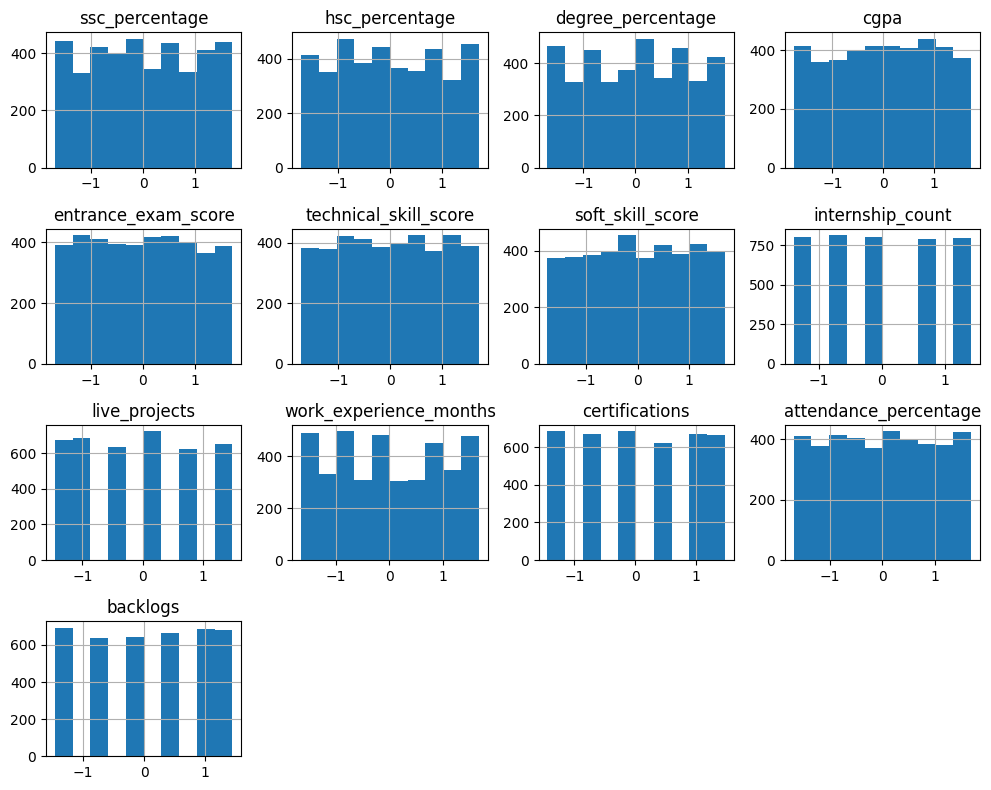

In [76]:
x_train[num_cols].hist(figsize=(10, 8))
plt.tight_layout()
plt.show()

In [34]:
x_test.describe().T

,count,mean,std,min,25%,50%,75%,max
ssc_percentage,1000.0,72.64200,13.214858,50.0,61.0000,73.0,84.00,95.0
hsc_percentage,1000.0,71.77400,12.821205,50.0,61.0000,72.0,83.00,94.0
degree_percentage,1000.0,71.80600,10.102595,55.0,63.0000,72.0,80.00,89.0
cgpa,1000.0,7.69522,1.246794,5.5,6.6275,7.7,8.78,9.8
entrance_exam_score,1000.0,69.06800,17.681063,40.0,54.0000,67.5,85.00,99.0
technical_skill_score,1000.0,69.67200,16.893840,40.0,55.0000,70.0,84.00,99.0
soft_skill_score,1000.0,69.34400,17.286714,40.0,54.0000,68.0,84.00,99.0
internship_count,1000.0,1.98800,1.401364,0.0,1.0000,2.0,3.00,4.0
live_projects,1000.0,2.57000,1.716405,0.0,1.0000,3.0,4.00,5.0
work_experience_months,1000.0,12.22900,7.255977,0.0,6.0000,12.0,19.00,24.0


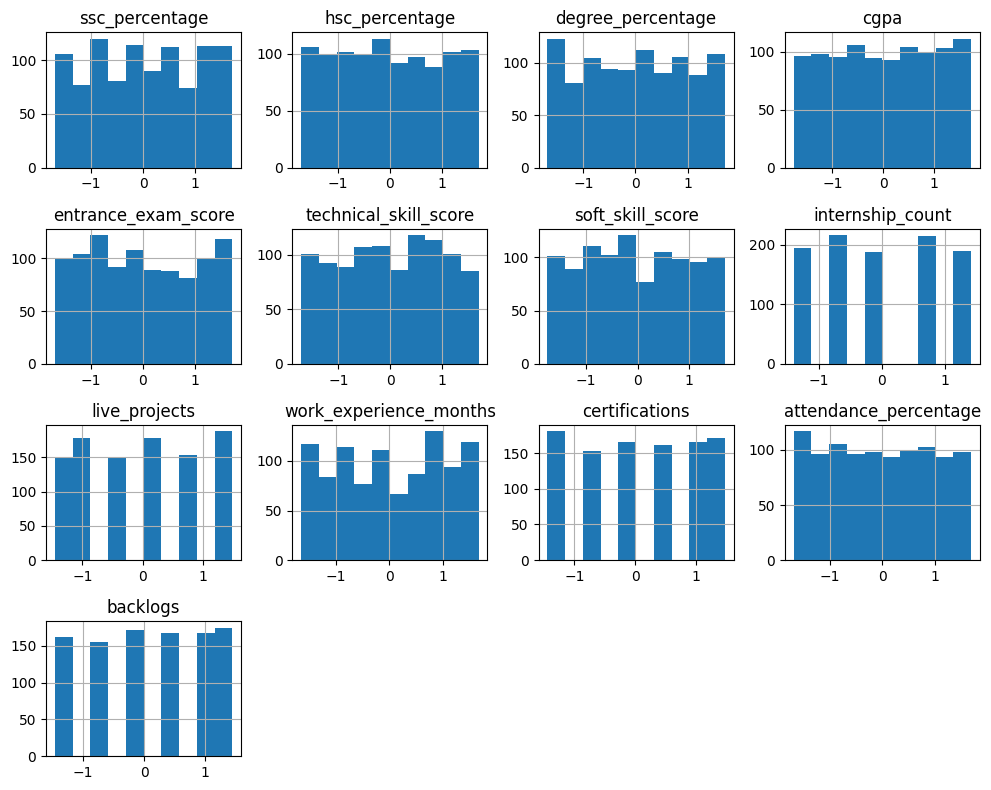

In [77]:
x_test[num_cols].hist(figsize=(10, 8))
plt.tight_layout()
plt.show()

In [35]:
# Define categorical and numerical columns
cat_cols = x_train.select_dtypes(include='object').columns
num_cols = x_train.select_dtypes(exclude='object').columns

## **A. CLASSIFICATION TASK**

### **DATA PREPROCESSING**

In [36]:
# scale numerical features
scaler = StandardScaler()
x_train[num_cols] = scaler.fit_transform(x_train[num_cols])
x_test[num_cols] = scaler.transform(x_test[num_cols])

Saya memutuskan melakukan sacling dengan Standard Scaler dikarena fitur fitur numerical pada dataset ini memiliki rentang nilai yang cukup bervariasi. Maka dari itu untuk menghidari algoritma melakukan kesalah dalam melakukan perhitungan, maka alangkah baiknya saya scale untuk menyamaratakan rentang. Standard scaler juga dipilih karena data yang kita punya tergolong cukup baik dan tidak ada outlier, maka aman untuk menggunakan StandardScaler.

In [37]:
# use label map encoder for gender and extracurricular_activities
enc_gender = LabelEncoder()
enc_extracurricular = LabelEncoder()

x_train['gender'] = enc_gender.fit_transform(x_train['gender'])
x_train['extracurricular_activities'] = enc_extracurricular.fit_transform(x_train['extracurricular_activities'])
x_test['gender'] = enc_gender.transform(x_test['gender'])
x_test['extracurricular_activities'] = enc_extracurricular.transform(x_test['extracurricular_activities'])


Label Encoder dipilih untuk mengencode Categorical value. Karena Hanya binary value di masing masing fitur.

In [38]:
x_train

,gender,ssc_percentage,hsc_percentage,degree_percentage,cgpa,entrance_exam_score,technical_skill_score,soft_skill_score,internship_count,live_projects,work_experience_months,certifications,attendance_percentage,backlogs,extracurricular_activities
483,0,-1.619650,1.560951,-0.085579,-1.129183,-0.071379,-0.269313,1.402412,0.008667,1.485568,-0.677969,-0.278318,0.300951,-0.296419,0
638,0,-0.103958,0.860449,-1.386787,1.049640,-0.477519,-1.660589,-1.514843,-1.406396,-0.277543,1.251114,0.887413,-0.473199,0.863732,1
936,0,0.350750,-1.708056,1.415814,0.101973,0.798921,-1.254800,0.993996,-0.698864,0.310161,-0.402386,-1.444050,1.247133,-0.296419,0
2932,1,1.032812,1.405284,-0.085579,-1.396474,1.611201,1.643691,0.118820,-0.698864,1.485568,-1.091344,-1.444050,1.333150,1.443808,0
4154,1,1.108597,1.327451,-0.085579,0.903845,-1.231779,1.701661,-1.398152,0.716199,0.897864,-0.264594,-0.278318,-1.075315,0.863732,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1417,1,-0.482881,-0.384887,-0.686137,1.689518,-1.115739,0.716174,-1.514843,0.716199,-1.452951,-0.126803,0.887413,-0.387182,-0.296419,1
1958,1,-1.392297,-0.307053,1.315721,-1.339776,-1.173759,-1.196830,1.169031,-1.406396,-0.277543,0.148781,-0.861184,-0.817265,-0.296419,1
3175,0,-1.316512,0.782616,0.014513,-0.991488,0.044661,-0.501193,0.002130,0.008667,0.310161,1.251114,0.304547,-0.387182,0.863732,0
1878,0,0.199181,-0.618387,0.715164,1.349330,0.624861,-1.080891,-1.689878,-0.698864,0.897864,-1.504719,-1.444050,1.419167,1.443808,1


In [39]:
# SMOTE the imbalanced data
from imblearn.over_sampling import SMOTE
smote = SMOTE(random_state=42)
x_train_smote, y_train_smote = smote.fit_resample(x_train, y_train_class)

Saya menggunakan SMOTE untuk menghandle Imbalance data pada data training tujuannya adalah supaya model dapat mempelajari data secara merata tidak hanya condong ke kelas yang mayoritas (0) saja. Dengan melakukan Over Sampling saya ingin supaya kelas minoritas memiliki Proporsi yang sama dengan kelas mayoritas untuk dipelajari oleh mode.

In [40]:
x_train_smote

,gender,ssc_percentage,hsc_percentage,degree_percentage,cgpa,entrance_exam_score,technical_skill_score,soft_skill_score,internship_count,live_projects,work_experience_months,certifications,attendance_percentage,backlogs,extracurricular_activities
0,0,-1.619650,1.560951,-0.085579,-1.129183,-0.071379,-0.269313,1.402412,0.008667,1.485568,-0.677969,-0.278318,0.300951,-0.296419,0
1,0,-0.103958,0.860449,-1.386787,1.049640,-0.477519,-1.660589,-1.514843,-1.406396,-0.277543,1.251114,0.887413,-0.473199,0.863732,1
2,0,0.350750,-1.708056,1.415814,0.101973,0.798921,-1.254800,0.993996,-0.698864,0.310161,-0.402386,-1.444050,1.247133,-0.296419,0
3,1,1.032812,1.405284,-0.085579,-1.396474,1.611201,1.643691,0.118820,-0.698864,1.485568,-1.091344,-1.444050,1.333150,1.443808,0
4,1,1.108597,1.327451,-0.085579,0.903845,-1.231779,1.701661,-1.398152,0.716199,0.897864,-0.264594,-0.278318,-1.075315,0.863732,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
6609,0,-0.098721,-1.442353,1.515907,0.383513,-0.741598,-0.371270,1.372237,-0.772047,1.485568,-0.331124,-0.740608,0.134861,-0.356418,1
6610,1,1.471902,0.021899,0.036155,1.250737,-1.359776,0.645082,1.027702,-0.275780,-0.277543,0.620345,0.887413,0.111191,-1.456569,0
6611,0,-0.639445,0.960807,-0.913454,0.522119,-0.440114,0.269191,1.370782,-0.374901,1.057168,-0.614878,1.470279,-1.302803,-0.876494,1
6612,0,0.026066,-0.386318,1.059519,0.279571,1.534552,1.323531,1.051268,-0.854648,1.027265,-0.785422,-0.534988,1.219516,-0.876494,0


C:\Users\Tuf Gaming\AppData\Local\Temp\ipykernel_1268\1039275163.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(x=y_train_smote, palette='viridis')


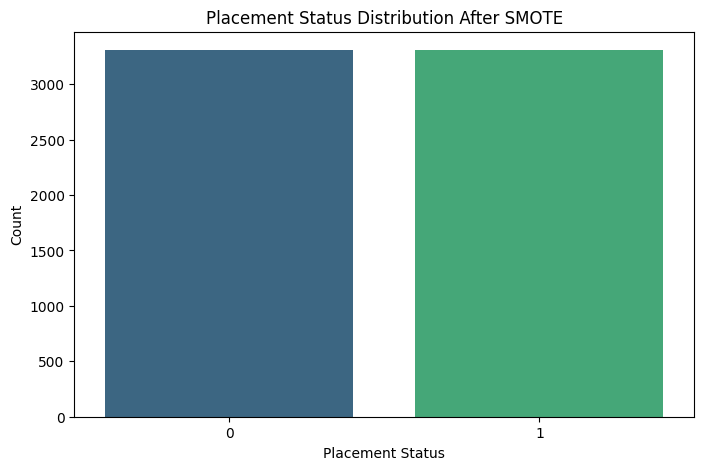

In [41]:
# Check target distribution plot for 'Credit_Score' after SMOTE
plt.figure(figsize=(8,5))
sns.countplot(x=y_train_smote, palette='viridis')
plt.title('Placement Status Distribution After SMOTE')
plt.xlabel('Placement Status')
plt.ylabel('Count')
plt.show()

### **MODELING CLASSIFICATION**

#### **Training RandomFOrest with imbalance data**

In [42]:
# training with imbalance data
rf = RandomForestClassifier(random_state=42)

param_rf = {
    'n_estimators': [100, 200, 300],
    'max_depth': [10, 20, None],
    'min_samples_split': [2, 5, 10],
    'criterion': ['gini', 'entropy']
}

grid_rf1= GridSearchCV(rf, param_rf, cv=5,scoring='f1_weighted',n_jobs=-1)

# Train with non-smote data
grid_rf1.fit(x_train, y_train_class)
best_rf1 = grid_rf1.best_estimator_
rf_pred1 = best_rf1.predict(x_test)

In [43]:
best_rf1

RandomForestClassifier(criterion='entropy', max_depth=10, random_state=42)

In [44]:
print("\n--- PERFORMANCE RANDOM FOREST---")
print(f"Accuracy: {accuracy_score(y_test_class, rf_pred1):.4f}")
print(classification_report(y_test_class, rf_pred1))


--- PERFORMANCE RANDOM FOREST---
Accuracy: 1.0000
              precision    recall  f1-score   support

           0       1.00      1.00      1.00       827
           1       1.00      1.00      1.00       173

    accuracy                           1.00      1000
   macro avg       1.00      1.00      1.00      1000
weighted avg       1.00      1.00      1.00      1000



AUC-ROC for Random Forest: 1.0000


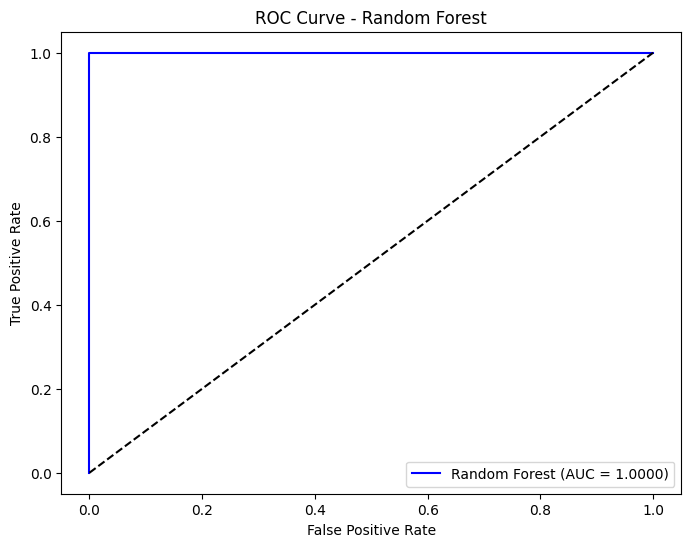

In [45]:
# Check AUC-ROC for Random Forest and visualize the ROC curve for imbalance
from sklearn.metrics import roc_auc_score, roc_curve
y_prob_rf1 = best_rf1.predict_proba(x_test)[:, 1]
auc_rf1 = roc_auc_score(y_test_class, y_prob_rf1)
print(f"AUC-ROC for Random Forest: {auc_rf1:.4f}")

fpr_rf1, tpr_rf1, _ = roc_curve(y_test_class, y_prob_rf1)
plt.figure(figsize=(8,6))
plt.plot(fpr_rf1, tpr_rf1, label=f'Random Forest (AUC = {auc_rf1:.4f})', color='blue')
plt.plot([0, 1], [0, 1], 'k--')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curve - Random Forest')
plt.legend()
plt.show()

Saya menggunakan dan melihat metric ROC-AUC untuk task klasifikasi, akan tetapi saya sadar bahwa metric ini dirasa kurang cocok untuk Data testing yang imbalance. Karena Dia akan lebih condong ke Kelas mayoritas.

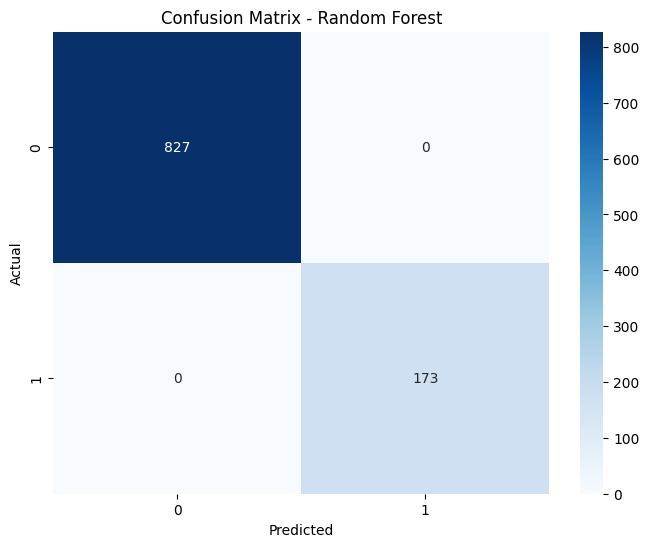

In [46]:
# Confusion Matrix for Random Forest imbalance
cm_rf = confusion_matrix(y_test_class, rf_pred1)
plt.figure(figsize=(8,6))
sns.heatmap(cm_rf, annot=True, fmt='d', cmap='Blues')
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.title('Confusion Matrix - Random Forest')
plt.show()

#### **Training RandomForest with SMOTE data**

In [47]:
#Train with smote data
grid_rf = GridSearchCV( rf, param_rf, cv=5, scoring='f1_weighted', n_jobs=-1)
grid_rf.fit(x_train_smote, y_train_smote)
best_rf = grid_rf.best_estimator_

rf_pred = best_rf.predict(x_test)

In [48]:
print("\n--- PERFORMANCE RANDOM FOREST SMOTE---")
print(f"Accuracy: {accuracy_score(y_test_class, rf_pred):.4f}")
print(classification_report(y_test_class, rf_pred))


--- PERFORMANCE RANDOM FOREST SMOTE---
Accuracy: 1.0000
              precision    recall  f1-score   support

           0       1.00      1.00      1.00       827
           1       1.00      1.00      1.00       173

    accuracy                           1.00      1000
   macro avg       1.00      1.00      1.00      1000
weighted avg       1.00      1.00      1.00      1000



Untuk classification report menunjukkan bahwa hasil dari training dan ketika testing menunujukkan hasil yang sempurna. Tetpi sebenarnya saya lebih berfokus ke metric recall, karena recall itu ingin melihat dari berapa yang benar (true), berapa yang kita berhasil tebak (true).  
Alasannya adalah kita tidak ingin model menebak mahasiswa yang seharusnya memang layak mendapat pekerjaan tetapi malah ditebak 'Not Place' (recall jelek). artinya kita membuang potensi yang ada. 

Berdasarkan hasil Training dengan Random Forest dengan data SMOTE dan yang tidak menghasilkan hasil yang sama dan sempurna. Hal ini mungkin saja terjadi karena data yang kita gunakan sudah terlalu bersih dan siap pakai, lalu bisa dikatakan bahwa data yang kita gunakan ini bersifat sintetik dan hal ini didukung dengan value data yang memiliki varians yang kecil lalu didukung pula dengan distribusi yang uniform.  Tak lupa menurut saya hal ini bisa terjadi karena saya menggunakan model Random Forest yang merupakan model ensemble yang bisa menangkpa pattern non-linear.

AUC-ROC for Random Forest: 1.0000


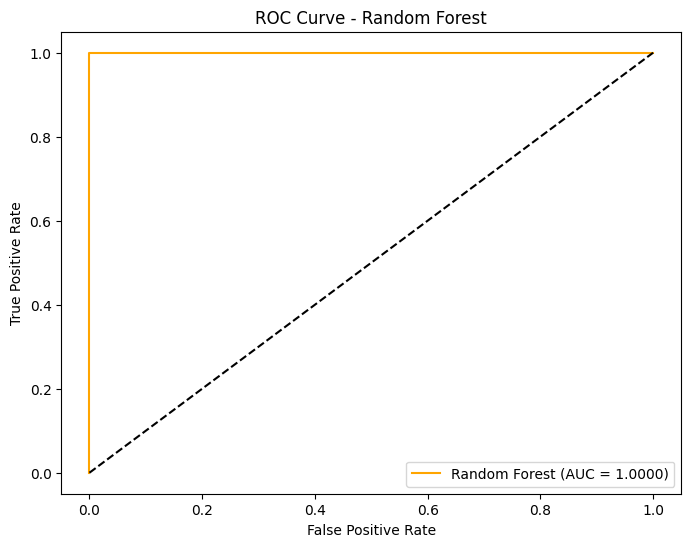

In [49]:
# Check AUC-ROC for Random Forest and visualize the ROC curve for SMOTE
y_prob_rf = best_rf.predict_proba(x_test)[:, 1]
auc_rf = roc_auc_score(y_test_class, y_prob_rf)
print(f"AUC-ROC for Random Forest: {auc_rf:.4f}")

fpr_rf, tpr_rf, _ = roc_curve(y_test_class, y_prob_rf)
plt.figure(figsize=(8,6))
plt.plot(fpr_rf, tpr_rf, label=f'Random Forest (AUC = {auc_rf:.4f})', color='orange')
plt.plot([0, 1], [0, 1], 'k--')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curve - Random Forest')
plt.legend()
plt.show()

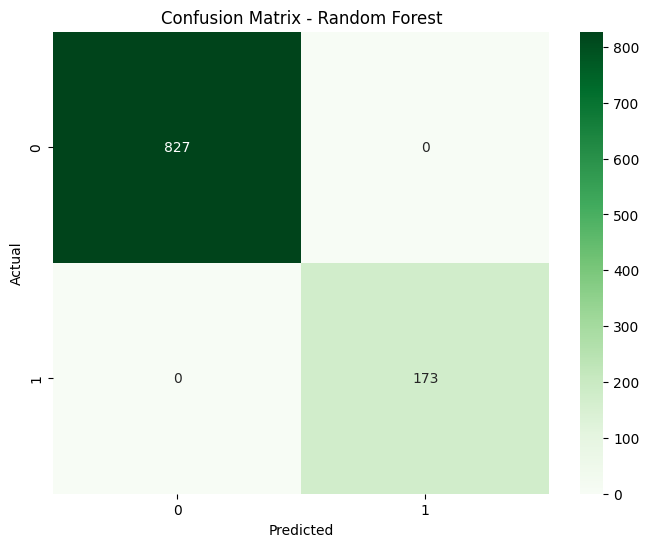

In [50]:
# Confusion Matrix for Random Forest SMOTE
cm_rf = confusion_matrix(y_test_class, rf_pred)
plt.figure(figsize=(8,6))
sns.heatmap(cm_rf, annot=True, fmt='d', cmap='Greens')
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.title('Confusion Matrix - Random Forest')
plt.show()

In [75]:
# Crosss Validaton for Random Forest (SMOTE)
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
scoring = {
    "accuracy": "accuracy",
    "f1": "f1",
    "precision": "precision",
    "recall": "recall",
    "roc_auc": "roc_auc"
}

cv_result = cross_validate(
    best_rf,
    x_train,
    y_train_class,
    cv=cv,
    scoring=scoring,
    n_jobs=-1,
    return_train_score=False
)
cv_summary = pd.DataFrame({
    "metric": list(scoring.keys()),
    "mean": [cv_result[f"test_{m}"].mean() for m in scoring.keys()],
    "std": [cv_result[f"test_{m}"].std() for m in scoring.keys()]
})

print("CrossVal SUMMARY Random Forest (SMOTE)")
display(cv_summary)

CrossVal SUMMARY Random Forest (SMOTE)


,metric,mean,std
0,accuracy,0.999750,0.000500
1,f1,0.999278,0.001444
2,precision,1.000000,0.000000
3,recall,0.998561,0.002878
4,roc_auc,1.000000,0.000000


Melihat hasil yang sangat sempurna, saya mencoba mencari tau apkah ini hasil overfit atau tidak. maka saya menggunakna Cross-validation untuk melihatnya. Tapi hasilnya menunjukan metric yang baik. artinya model saya tidak overfit.

#### **Training Logistic Regression**

In [52]:
# train with logistic regression
from sklearn.linear_model import LogisticRegression
lr = LogisticRegression(random_state=42, max_iter=1000)
param_lr = {'C': [0.01, 0.1, 1, 10],
            'solver': ['liblinear', 'lbfgs']
            }

grid_lr = GridSearchCV(lr, param_lr, cv=5, scoring='f1_weighted', n_jobs=-1)
grid_lr.fit(x_train_smote, y_train_smote)
best_lr = grid_lr.best_estimator_
lr_pred = best_lr.predict(x_test)

In [53]:
print("\n--- PERFORMANCE LOGISTIC REGRESSION SMOTE---")
print(f"Accuracy: {accuracy_score(y_test_class, lr_pred):.4f}")
print(classification_report(y_test_class, lr_pred))


--- PERFORMANCE LOGISTIC REGRESSION SMOTE---
Accuracy: 0.8450
              precision    recall  f1-score   support

           0       0.96      0.85      0.90       827
           1       0.53      0.84      0.65       173

    accuracy                           0.84      1000
   macro avg       0.75      0.84      0.78      1000
weighted avg       0.89      0.84      0.86      1000



Nah dugaan saya sebelumnya terbukti di mana ketika saya mencoba menggunakna algoritma linear, Model kurang dapat menangkap polanya sebaik Random Forest. Maka hasil sempurna yang didapat pada algoritma sebelumnya didukung karena algoritma ensemble yang bisa menangkap patter non-linear.

AUC-ROC for Logistic Regression: 0.9301


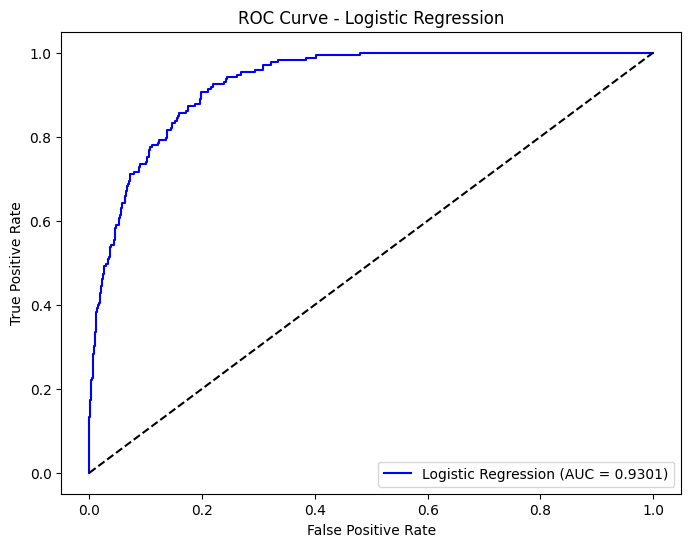

In [54]:
# Check AUC-ROC for Logistic Regression and visualize the ROC curve for SMOTE
y_prob_lr = best_lr.predict_proba(x_test)[:, 1]
auc_lr = roc_auc_score(y_test_class, y_prob_lr)
print(f"AUC-ROC for Logistic Regression: {auc_lr:.4f}")

fpr_lr, tpr_lr, _ = roc_curve(y_test_class, y_prob_lr)
plt.figure(figsize=(8,6))
plt.plot(fpr_lr, tpr_lr, label=f'Logistic Regression (AUC = {auc_lr:.4f})', color='blue')
plt.plot([0, 1], [0, 1], 'k--')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curve - Logistic Regression')
plt.legend()
plt.show()

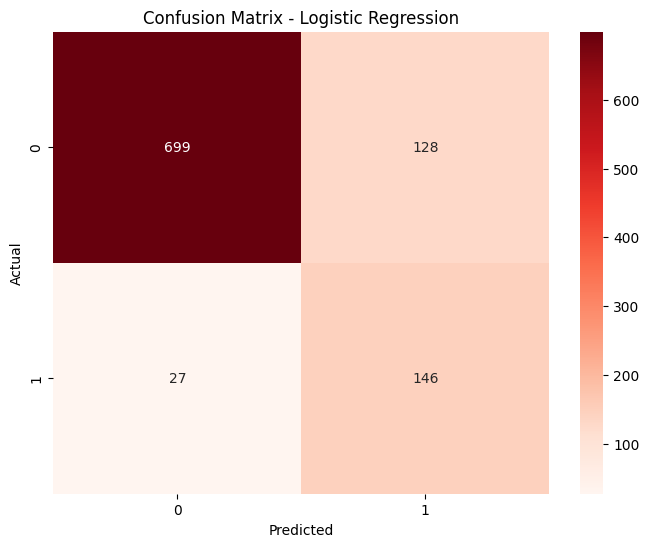

In [55]:
# Confusion Matrix for Logistic Regression with SMOTE
cm_lr = confusion_matrix(y_test_class, lr_pred)
plt.figure(figsize=(8,6))
sns.heatmap(cm_lr, annot=True, fmt='d', cmap='Reds')
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.title('Confusion Matrix - Logistic Regression')
plt.show()

In [73]:
# Cross-validation for Logistic Regression
cv_lr = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
scoring = {
    "accuracy": "accuracy",
    "f1": "f1",
    "precision": "precision",
    "recall": "recall",
    "roc_auc": "roc_auc"
}

cv_result = cross_validate(
    best_lr,
    x_train,
    y_train_class,
    cv=cv_lr,
    scoring=scoring,
    n_jobs=-1,
    return_train_score=False
)
cv_summary = pd.DataFrame({
    "metric": list(scoring.keys()),
    "mean": [cv_result[f"test_{m}"].mean() for m in scoring.keys()],
    "std": [cv_result[f"test_{m}"].std() for m in scoring.keys()]
})

print("CrossVal SUMMARY in Logistic Regression")
display(cv_summary)

CrossVal SUMMARY in Logistic Regression


,metric,mean,std
0,accuracy,0.891000,0.010994
1,f1,0.645864,0.028294
2,precision,0.744084,0.058122
3,recall,0.572891,0.029788
4,roc_auc,0.930385,0.014358


#### **Training XGboost with SMOTE**

In [57]:
xgb = XGBClassifier(random_state=42, use_label_encoder=False, eval_metric='logloss')
param_xgb = {
    'n_estimators': [100, 200, 300],
    'max_depth': [3, 6, 10],
    'learning_rate': [0.01, 0.1, 0.2],
    'subsample': [0.8, 1]
}
grid_xgb = GridSearchCV(xgb, param_xgb, cv=5, scoring='f1_weighted', n_jobs=-1)
grid_xgb.fit(x_train_smote, y_train_smote)
best_xgb = grid_xgb.best_estimator_
xgb_pred = best_xgb.predict(x_test)

c:\Users\Tuf Gaming\buat-coding\env\ml\Lib\site-packages\xgboost\training.py:200: UserWarning: [18:16:25] WARNING: C:\actions-runner\_work\xgboost\xgboost\src\learner.cc:782: 
Parameters: { "use_label_encoder" } are not used.

  bst.update(dtrain, iteration=i, fobj=obj)


In [58]:
best_xgb

XGBClassifier(base_score=None, booster=None, callbacks=None,
              colsample_bylevel=None, colsample_bynode=None,
              colsample_bytree=None, device=None, early_stopping_rounds=None,
              enable_categorical=False, eval_metric='logloss',
              feature_types=None, feature_weights=None, gamma=None,
              grow_policy=None, importance_type=None,
              interaction_constraints=None, learning_rate=0.01, max_bin=None,
              max_cat_threshold=None, max_cat_to_onehot=None,
              max_delta_step=None, max_depth=3, max_leaves=None,
              min_child_weight=None, missing=nan, monotone_constraints=None,
              multi_strategy=None, n_estimators=100, n_jobs=None,
              num_parallel_tree=None, ...)

AUC-ROC for XGBoost: 1.0000


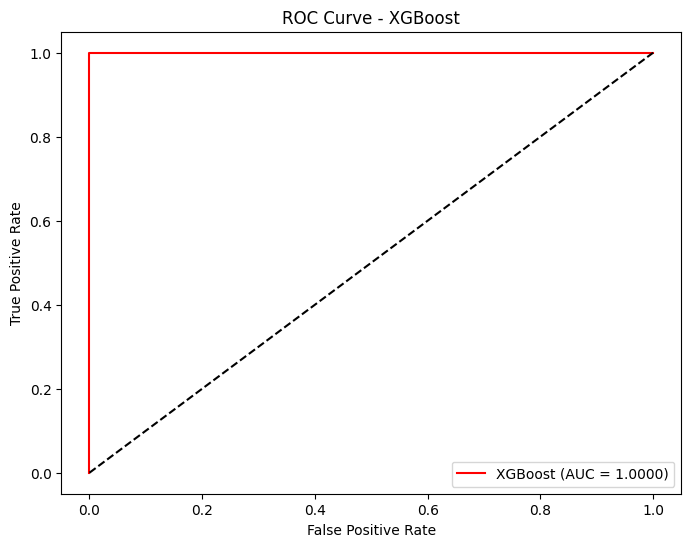

In [59]:
# Check AUC-ROC for XGboost and visualize the ROC curve for SMOTE
y_prob_xgb = best_xgb.predict_proba(x_test)[:, 1]
auc_xgb = roc_auc_score(y_test_class, y_prob_xgb)
print(f"AUC-ROC for XGBoost: {auc_xgb:.4f}")

fpr_xgb, tpr_xgb, _ = roc_curve(y_test_class, y_prob_xgb)
plt.figure(figsize=(8,6))
plt.plot(fpr_xgb, tpr_xgb, label=f'XGBoost (AUC = {auc_xgb:.4f})', color='red')
plt.plot([0, 1], [0, 1], 'k--')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curve - XGBoost')
plt.legend()
plt.show()

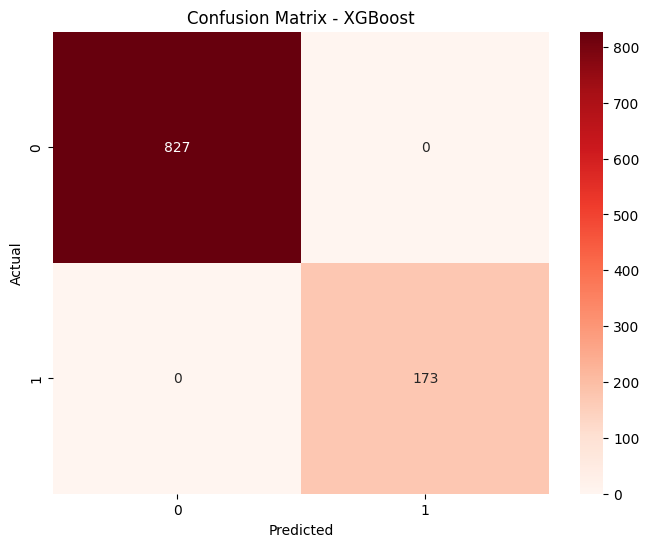

In [60]:
# Confusion Matrix for XGboost with SMOTE
cm_xgb = confusion_matrix(y_test_class, xgb_pred)
plt.figure(figsize=(8,6))
sns.heatmap(cm_xgb, annot=True, fmt='d', cmap='Reds')
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.title('Confusion Matrix - XGBoost')
plt.show()

In [74]:
# Cross-validation for XGBoost
cv_xgb = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
scoring = {
    "accuracy": "accuracy",
    "f1": "f1",
    "precision": "precision",
    "recall": "recall",
    "roc_auc": "roc_auc"
}

cv_result = cross_validate(
    best_xgb,
    x_train,
    y_train_class,
    cv=cv_xgb,
    scoring=scoring,
    n_jobs=-1,
    return_train_score=False
)
cv_summary = pd.DataFrame({
    "metric": list(scoring.keys()),
    "mean": [cv_result[f"test_{m}"].mean() for m in scoring.keys()],
    "std": [cv_result[f"test_{m}"].std() for m in scoring.keys()]
})

print("CrossVal SUMMARY XGBoost")
display(cv_summary)

CrossVal SUMMARY XGBoost


,metric,mean,std
0,accuracy,0.999750,0.000500
1,f1,0.999278,0.001444
2,precision,1.000000,0.000000
3,recall,0.998561,0.002878
4,roc_auc,0.999933,0.000135


Terakhir sebagai perbandingan saya mencoba membandingkan model ensemble lagi dengan menggunana XGBosst. Ternyata benar bahwa model Ensemble memberikan hasil yang sangat baik dan juga ternyata data kita memilii pattern non-linear. Akan tetapi meskipun memiliki hasil yang sama. Saya tetap meilih menggunakna model RandomForest dikarenakan RandomForest memiliki kompleksitas yang jauh lebih ringan, daripada XGBoost.

## **B. REGRESSION TASK**

### **DATA PREPROCESSING**

In [ ]:
filter = y_train_class == 1
x_train_reg = x_train.loc[filter]
y_train_reg = y_train_reg.loc[filter]

KArena saya menggunakna konsep 2 step sequence untuk case ini. Maka untuk regresinya saya memutuskan melakukan filtering di mana hanya mahasiswa yang mendapat status 'Placed' yang aan diprediksi salarynya, di luar itu akan mendapat 0.

In [ ]:
x_train_reg

,gender,ssc_percentage,hsc_percentage,degree_percentage,cgpa,entrance_exam_score,technical_skill_score,soft_skill_score,internship_count,live_projects,work_experience_months,certifications,attendance_percentage,backlogs,extracurricular_activities
4751,1,-0.937589,1.327451,1.315721,0.968643,-0.245439,0.658204,0.235510,0.716199,0.897864,0.699947,-1.444050,-0.989299,-1.456569,1
3096,0,-0.634450,-1.163222,1.515907,0.215369,-1.695939,0.890083,0.877306,0.008667,0.897864,1.526697,-1.444050,1.075100,-0.876494,0
4641,1,-0.482881,-0.384887,-0.485951,1.373629,0.566841,0.774143,-0.814702,-1.406396,1.485568,-0.264594,-0.861184,0.214934,-1.456569,1
4931,1,0.274966,1.093950,1.616000,-0.367810,-1.521879,1.643691,0.002130,1.423730,-0.277543,1.388905,-0.861184,0.042901,-1.456569,1
1344,1,-0.937589,-1.007555,-0.886323,-0.238215,0.276741,1.585721,-0.347941,-1.406396,0.897864,-0.264594,-0.278318,-1.247348,-0.296419,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
4666,0,-0.407096,-0.462720,-0.385858,0.312566,1.495161,-0.501193,0.993996,-1.406396,-0.865247,1.664489,1.470279,-1.677431,-1.456569,0
369,1,-0.937589,-0.696221,-0.485951,1.244033,1.553181,1.411812,1.460757,1.423730,-0.277543,-0.126803,0.304547,0.731034,-0.876494,1
2088,0,-1.013373,-1.007555,1.115535,1.487025,1.437141,0.948053,-0.347941,0.008667,0.897864,0.975530,1.470279,-1.247348,-0.296419,0
3710,0,-0.331312,1.171783,-0.886323,0.353065,-0.361479,0.426325,1.402412,0.008667,0.897864,-0.540178,1.470279,-1.419382,-0.876494,1


### **MODELING REGRESSION**

#### **Training RandomForest Regressor**

In [64]:
rfr = RandomForestRegressor(n_estimators=600,random_state=42, criterion='squared_error', max_depth=20, min_samples_split=5)
rfr.fit(x_train_reg, y_train_reg)

RandomForestRegressor(max_depth=20, min_samples_split=5, n_estimators=600,
                      random_state=42)

In [65]:
rfr_pred = np.zeros(len(x_test), dtype=float)
placed_pred_idx = np.where(rf_pred1 == 1)[0]

if len(placed_pred_idx) > 0:
    rfr_pred[placed_pred_idx] = rfr.predict(x_test.iloc[placed_pred_idx])

In [66]:
# Evaluate regression model
mse = mean_squared_error(y_test_reg, rfr_pred)
r2 = r2_score(y_test_reg, rfr_pred)
print("PERFORMANCE RANDOM FOREST REGRESSOR")
print(f"Mean Squared Error: {mse:.4f}")
print(f"RMSE : {np.sqrt(mse):.4f}")
print(f"R^2 Score: {r2:.4f}")

PERFORMANCE RANDOM FOREST REGRESSOR
Mean Squared Error: 2.1230
RMSE : 1.4571
R^2 Score: 0.8537


Hasil dari model ensemble menunjukkan bahwa Rata-rata errornya ada di angka 2,1.

#### **Training with Linear Regression**

In [67]:
liner_reg = LinearRegression()
liner_reg.fit(x_train_reg, y_train_reg)

LinearRegression()

In [68]:
liner_reg_pred = np.zeros(len(x_test), dtype=float)
if len(placed_pred_idx) > 0:
    liner_reg_pred[placed_pred_idx] = liner_reg.predict(x_test.iloc[placed_pred_idx])


In [69]:
# Evaluate regression model
mse_linreg = mean_squared_error(y_test_reg, liner_reg_pred)
r2_linreg = r2_score(y_test_reg, liner_reg_pred)
print("PERFORMANCE LINEAR REGRESSION")
print(f"Mean Squared Error: {mse_linreg:.4f}")
print(f"RMSE : {np.sqrt(mse_linreg):.4f}")
print(f"R^2 Score: {r2_linreg:.4f}")

PERFORMANCE LINEAR REGRESSION
Mean Squared Error: 2.0065
RMSE : 1.4165
R^2 Score: 0.8618


Ketika saya menggunakna algoritma Linear, saya mendapatkan Rata-rata Kuadrat errornya ada di angka 2. Yang menunjukkan bahwa errornya memiliki nilai yang lebih kecil daripada model randoForest Regressor.

#### **Training with SVR**

In [70]:
svr = SVR(kernel='rbf')
svr.fit(x_train_reg, y_train_reg)

SVR()

In [71]:
# testing
svr_pred = np.zeros(len(x_test), dtype=float)
if len(placed_pred_idx) > 0:
    svr_pred[placed_pred_idx] = svr.predict(x_test.iloc[placed_pred_idx])


In [72]:
# evaluate regression model
mse_svr = mean_squared_error(y_test_reg, svr_pred)
r2_svr = r2_score(y_test_reg, svr_pred)
print("PERFORMANCE SUPPORT VECTOR REGRESSOR")
print(f"Mean Squared Error: {mse_svr:.4f}")
print(f"RMSE : {np.sqrt(mse_svr):.4f}")
print(f"R^2 Score: {r2_svr:.4f}")

PERFORMANCE SUPPORT VECTOR REGRESSOR
Mean Squared Error: 2.1435
RMSE : 1.4641
R^2 Score: 0.8523


Lalu untuk algoritma ketiga saya mencoba lagi model linear dengan algoritma Support Vector Regressor untuk melihat bagaimana hasilnya. DAn ternyata memang Algoritma linear lebih cocok untuk regression task dan saya memilih algoritma Linear Regression sebagai model terbaik.